# H II 領域の検証計算

EQCLib の単一セル計算から、平衡温度、H・He・C・O・Si の電離分率、冷却・加熱率、化学反応率を描きます。計算には PEGASE2 の太陽金属量の電離スペクトルと case B 再結合を使い、ダストと分子を省いています。

再計算するには EQCLib のルートで `make -C test hii` を実行します。計算には既定で同梱のスペクトルを使い、このノートブックは計算済み CSV を読み込みます。 [スペクトルの指定方法](../README.md#pegase2-のスペクトルを指定する)

保存済みの結果を使う場合は、最初のコードセルの `run_dir` に CSV があるディレクトリを指定してください。計算条件と CSV の詳細は [H II 領域の検証手順](../test/README.md#h-ii-領域の検証計算と描画) にあります。

In [1]:
%matplotlib inline

import sys
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np

cwd = Path.cwd()
repo_root = next(
    (directory for directory in (cwd, *cwd.parents)
     if (directory / "plot" / "PlotHIIRegion.ipynb").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("EQCLib のリポジトリ内からノートブックを実行してください。")

run_dir = repo_root / "test" / "out" / "hii"
ion_fraction_density = 100.0  # cm⁻³

plot_dir = str(repo_root / "plot")
if plot_dir not in sys.path:
    sys.path.insert(0, plot_dir)

from plot_style import BLUE, GRAY, GREEN, ORANGE, PLOT_STYLE
from plot_hii_region import load_results, plot_equilibrium, plot_reactions, plot_thermal

try:
    equilibrium, thermal, reactions, reference = load_results(run_dir)
except FileNotFoundError as error:
    raise FileNotFoundError(
        f"{run_dir} に必要な CSV がありません。EQCLib のルートで make -C test hii を実行してください。"
    ) from error

print(f"熱平衡 {len(equilibrium)} 条件、温度走査 {len(thermal)} 点")

熱平衡 108 条件、温度走査 121 点


## 平衡温度と電離分率

温度の帯は同じ金属量と電離パラメータで密度を変えたときの範囲です。電離分率は `ion_fraction_density` で指定した密度を表示します。

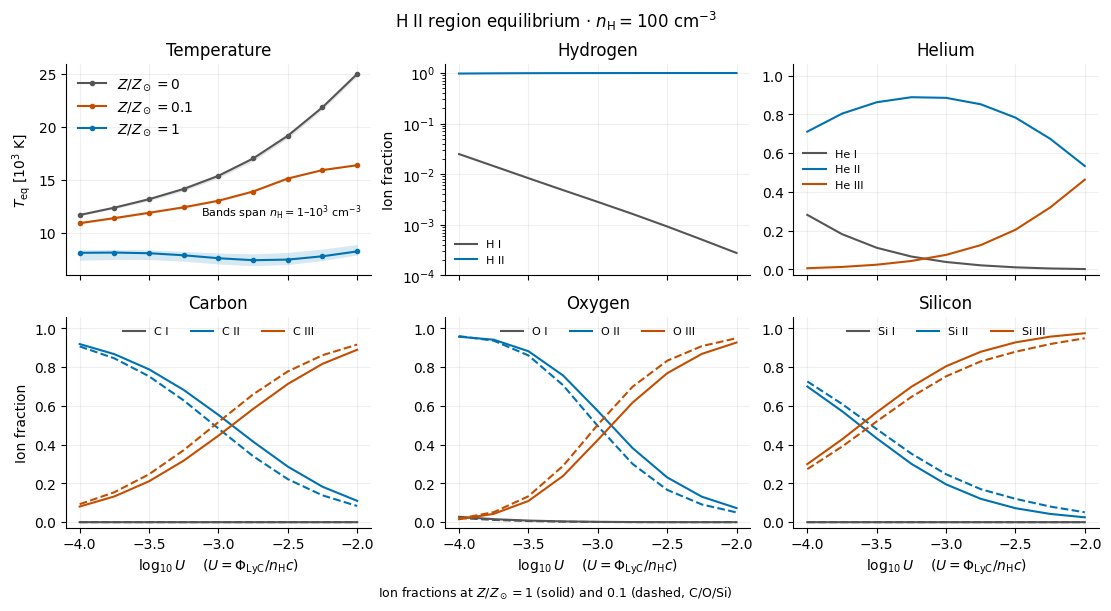

In [2]:
densities = np.unique(equilibrium["nH"])
if ion_fraction_density not in densities:
    raise ValueError(f"ion_fraction_density を次の密度から選んでください。{densities} cm⁻³")

with plt.rc_context(PLOT_STYLE):
    fig = plot_equilibrium(equilibrium, ion_fraction_density)
    display(fig)
    plt.close(fig)

## 冷却と加熱

冷却・加熱率を水素核密度の二乗で規格化しています。縦の点線は全加熱と全冷却が釣り合う平衡温度です。

平衡温度 7,589 K、[O II] と [O III] の冷却割合 68.1%


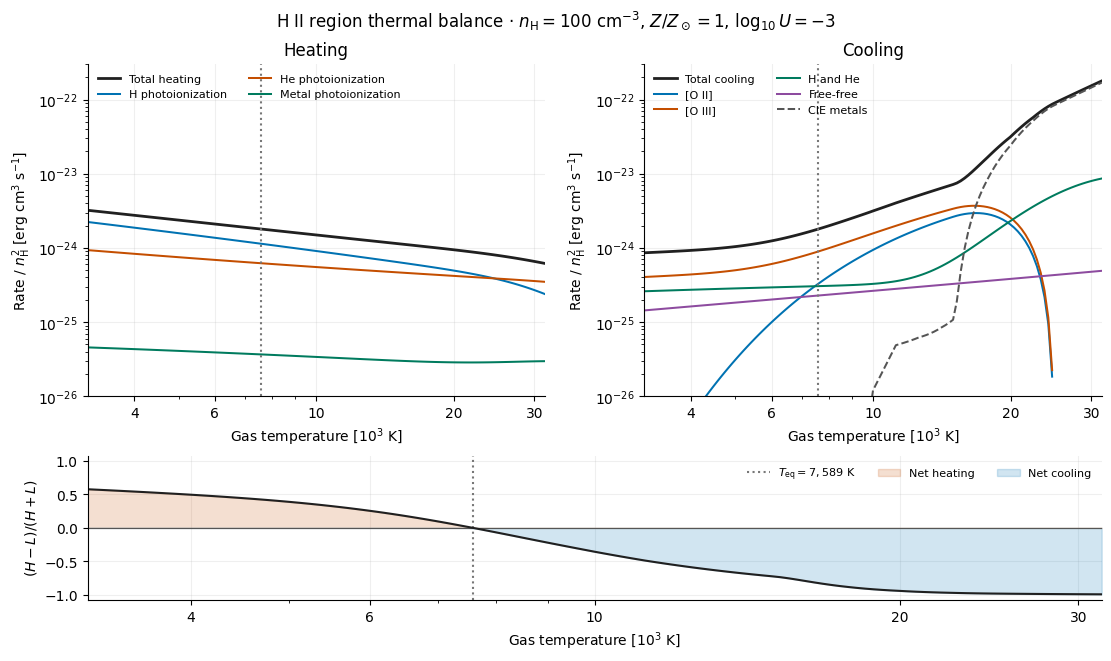

In [3]:
oxygen_fraction = (reference["L_OII"] + reference["L_OIII"]) / reference["L_tot"]
print(f'平衡温度 {reference["T"]:,.0f} K、[O II] と [O III] の冷却割合 {oxygen_fraction:.1%}')

with plt.rc_context(PLOT_STYLE):
    fig = plot_thermal(thermal, reference)
    display(fig)
    plt.close(fig)

## 化学反応率

各イオン段階について、光電離、電子衝突電離、電子再結合の反応率を温度に対して比較します。H と O では、O⁰ + H⁺ ⇄ O⁺ + H⁰ と O²⁺ + H⁰ → O⁺ + H⁺ の電荷交換による電離と再結合も描きます。反応率は水素核密度の二乗で規格化しています。

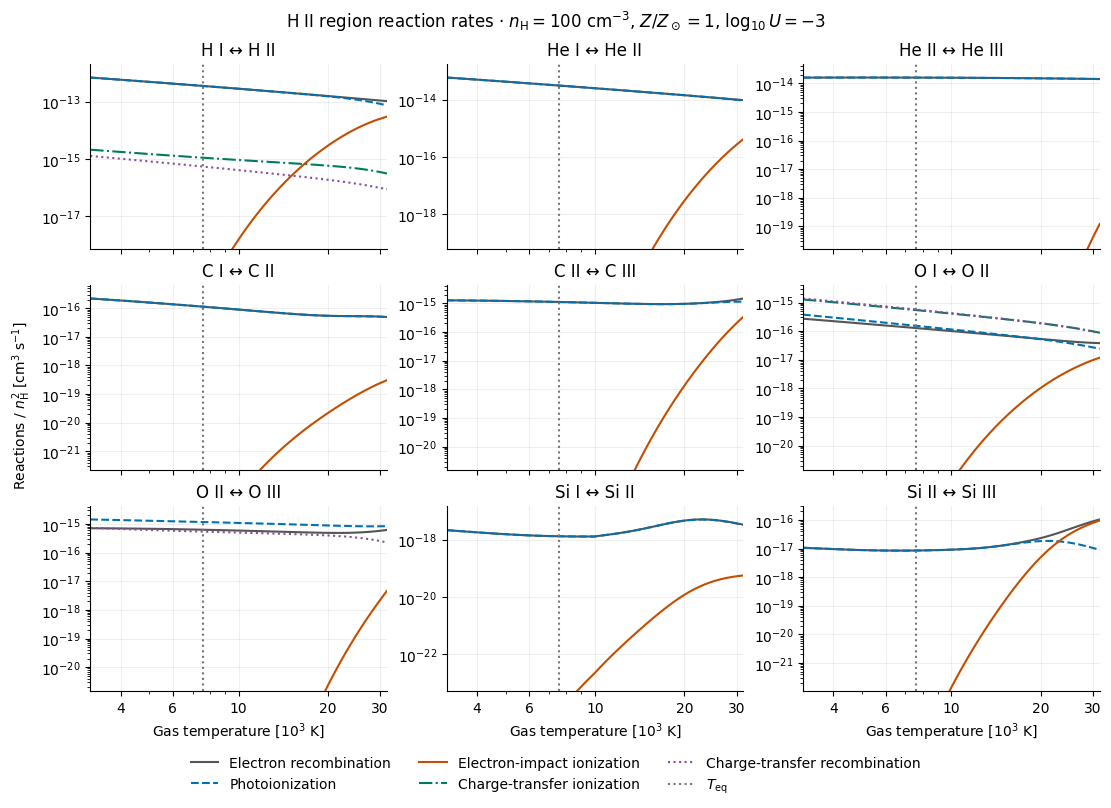

In [4]:
with plt.rc_context(PLOT_STYLE):
    fig = plot_reactions(reactions, reference)
    display(fig)
    plt.close(fig)

## Cloudy C23.01 との単一ゾーン比較

密度、電離パラメータ、H・He・C・O・Si のガス組成を EQCLib の CSV から Cloudy に渡しました。ダストと分子を含めず、PEGASE2 の同じ18時点（0〜30 Myr）を各時点の水素電離光子数で規格化した後に平均しています。Cloudy では case B と厚さ 1 cm の1ゾーンを指定し、入射光の減衰が無視できることを確認しました。スペクトルの補間と光電離・再結合などの計算には各コードの実装を使っています。

Cloudy の実行方法は [Cloudy との比較手順](../test/README.md#cloudy-との比較) にあります。このノートブックは再計算した CSV があれば優先し、それ以外の場合は [保存済みの参照結果](../test/hii/cloudy/cloudy_hii_c23.01.csv) を読み込みます。

In [5]:
from IPython.display import Markdown
from matplotlib.lines import Line2D
from plot_hii_region import load_csv

cloudy_file = run_dir / "cloudy" / "cloudy_equilibrium.csv"
if not cloudy_file.is_file():
    cloudy_file = repo_root / "test" / "hii" / "cloudy" / "cloudy_hii_c23.01.csv"

keys = ["nH", "Z_solar", "log_U"]
ceq_grid = np.sort(equilibrium, order=keys)
cloudy_grid = np.sort(load_csv(cloudy_file), order=keys)
if len(np.unique(ceq_grid[keys])) != len(ceq_grid):
    raise ValueError("EQCLib の比較キーが重複しています。")
for column in (*keys, "NLyn", "He_H", "C_H", "O_H", "Si_H"):
    np.testing.assert_allclose(ceq_grid[column], cloudy_grid[column], rtol=1e-11, atol=0,
                               err_msg=f"EQCLib と Cloudy の入力列 {column} を確認してください。")

metal_colors = {0.0: GRAY, 0.1: ORANGE, 1.0: BLUE}
ion_colors = (GRAY, BLUE, ORANGE, GREEN)
model_key = [Line2D([], [], color=GRAY, ls=style, label=name)
             for name, style in (("EQCLib", "-"), ("Cloudy", "--"))]
density_mask = ceq_grid["nH"] == ion_fraction_density
print(f"入力条件が一致したモデルは {len(cloudy_grid)} 件です。")

入力条件が一致したモデルは 108 件です。


### 平衡温度

全108条件の平衡温度を密度ごとに比較します。実線が EQCLib、破線が Cloudy です。

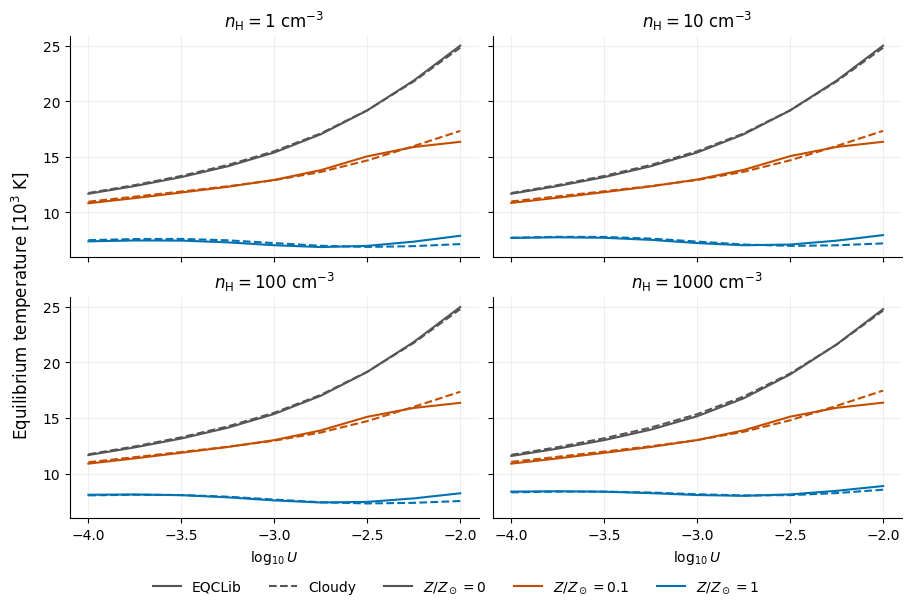

温度の相対差 (EQCLib/Cloudy − 1) は中央値 -0.6%。 絶対値が最大の条件では +10.5%（n_H=1 cm⁻³、Z/Z☉=1、log U=-2）。


In [6]:
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharex=True, sharey=True, layout="constrained")
    for ax, density in zip(axes.flat, densities):
        for z, color in metal_colors.items():
            mask = (ceq_grid["nH"] == density) & (ceq_grid["Z_solar"] == z)
            u = ceq_grid["log_U"][mask]
            ax.plot(u, ceq_grid["T"][mask] / 1e3, color=color)
            ax.plot(u, cloudy_grid["T"][mask] / 1e3, color=color, ls="--")
        ax.set_title(rf"$n_{{\rm H}}={density:g}$ cm$^{{-3}}$")
    metallicity_key = [Line2D([], [], color=color, label=rf"$Z/Z_\odot={z:g}$")
                       for z, color in metal_colors.items()]
    fig.legend(handles=model_key + metallicity_key, loc="outside lower center", ncol=5)
    for ax in axes[-1]:
        ax.set_xlabel(r"$\log_{10} U$")
        ax.set_xticks([-4, -3.5, -3, -2.5, -2])
    fig.supylabel(r"Equilibrium temperature [$10^3$ K]")
    display(fig)
    plt.close(fig)

relative_temperature = 100 * (ceq_grid["T"] / cloudy_grid["T"] - 1)
worst = np.argmax(np.abs(relative_temperature))
case = ceq_grid[worst]
print(f'温度の相対差 (EQCLib/Cloudy − 1) は中央値 {np.median(relative_temperature):+.1f}%。'
      f' 絶対値が最大の条件では {relative_temperature[worst]:+.1f}%'
      f'（n_H={case["nH"]:g} cm⁻³、Z/Z☉={case["Z_solar"]:g}、log U={case["log_U"]:g}）。')

### H・He・O の電離分率

冒頭の `ion_fraction_density` で選んだ密度を表示します。Cloudy については O IV〜O VI の合計も描いています。EQCLib は O III までを扱います。金属を含まない場合、酸素の電離分率は定義されません。

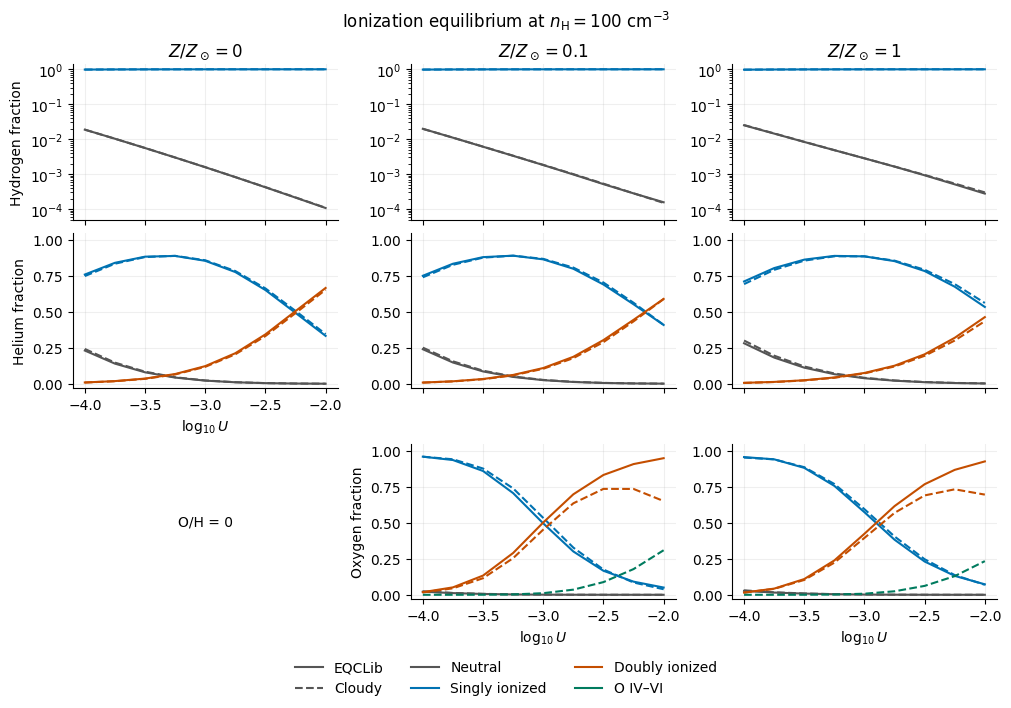

全グリッドでの HII 分率の最大絶対差は 0.04 パーセントポイント。
全グリッドでの HeIII 分率の最大絶対差は 2.99 パーセントポイント。
全グリッドでの OIII 分率の最大絶対差は 29.84 パーセントポイント。


In [7]:
ions_by_element = {
    "Hydrogen": ("HI", "HII"),
    "Helium": ("HeI", "HeII", "HeIII"),
    "Oxygen": ("OI", "OII", "OIII"),
}
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(3, 3, figsize=(10, 7), sharex=True, layout="constrained")
    for col, z in enumerate(metal_colors):
        mask = density_mask & (ceq_grid["Z_solar"] == z)
        u = ceq_grid["log_U"][mask]
        axes[0, col].set_title(rf"$Z/Z_\odot={z:g}$")
        for row, (element, ions) in enumerate(ions_by_element.items()):
            ax = axes[row, col]
            if element == "Oxygen" and z == 0:
                ax.set_axis_off()
                ax.text(0.5, 0.5, "O/H = 0", ha="center", va="center", transform=ax.transAxes)
                axes[1, col].tick_params(labelbottom=True)
                continue
            for ion, color in zip(ions, ion_colors):
                ax.plot(u, ceq_grid[ion][mask], color=color)
                ax.plot(u, cloudy_grid[ion][mask], color=color, ls="--")
            if element == "Oxygen":
                higher = sum(cloudy_grid[ion][mask] for ion in ("OIV", "OV", "OVI"))
                ax.plot(u, higher, color=ion_colors[3], ls="--")
            if element == "Hydrogen":
                ax.set(yscale="log", ylim=(5e-5, 1.4))
            else:
                ax.set(ylim=(-0.03, 1.05))
            if col == (1 if element == "Oxygen" else 0):
                ax.set_ylabel(f"{element} fraction")
    ion_key = [Line2D([], [], color=color, label=label) for color, label in
               zip(ion_colors, ("Neutral", "Singly ionized", "Doubly ionized", "O IV–VI"))]
    fig.legend(handles=model_key + ion_key, loc="outside lower center", ncol=3)
    fig.suptitle(rf"Ionization equilibrium at $n_{{\rm H}}={ion_fraction_density:g}$ cm$^{{-3}}$")
    for ax in (axes[1, 0], *axes[-1, 1:]):
        ax.set_xlabel(r"$\log_{10} U$")
        ax.set_xticks([-4, -3.5, -3, -2.5, -2])
    display(fig)
    plt.close(fig)

for ion in ("HII", "HeIII", "OIII"):
    max_difference = 100 * np.nanmax(np.abs(ceq_grid[ion] - cloudy_grid[ion]))
    print(f"全グリッドでの {ion} 分率の最大絶対差は {max_difference:.2f} パーセントポイント。")


### [O II]・[O III] の冷却率

各コードの平衡状態で熱収支に入る冷却率を比較します。EQCLib は温度による重み付きの5準位冷却、Cloudy は各イオンの正味の衝突線冷却を使用しています。金属なしの条件では両コードとも酸素冷却はゼロです。

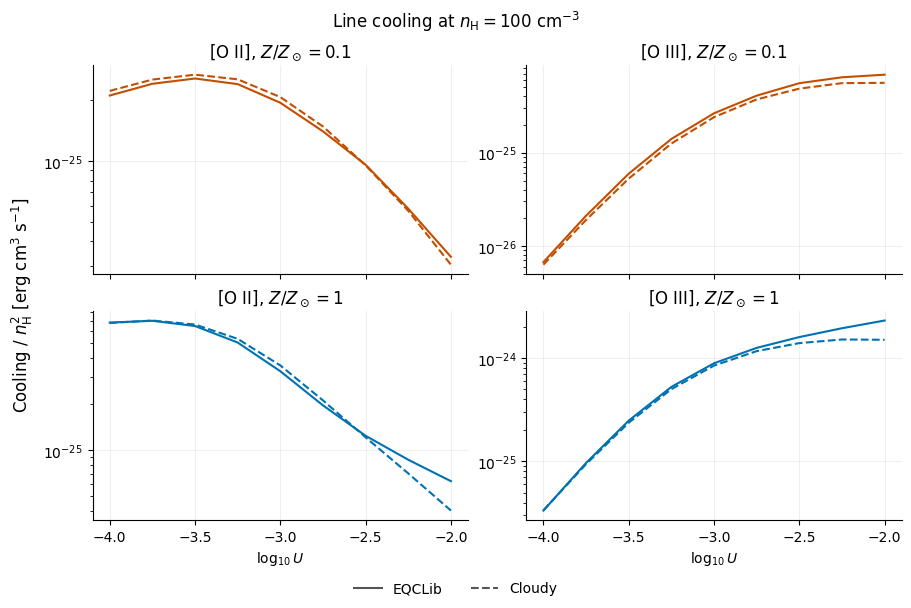

In [8]:
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharex=True, layout="constrained")
    for col, (ion, field) in enumerate((("[O II]", "L_OII"), ("[O III]", "L_OIII"))):
        for row, z in enumerate((0.1, 1.0)):
            ax = axes[row, col]
            mask = density_mask & (ceq_grid["Z_solar"] == z)
            u = ceq_grid["log_U"][mask]
            for data, style in ((ceq_grid, "-"), (cloudy_grid, "--")):
                rate = data[field][mask] / ion_fraction_density**2
                ax.plot(u, np.ma.masked_less_equal(rate, 0), color=metal_colors[z], ls=style)
            ax.set(title=rf"{ion}, $Z/Z_\odot={z:g}$", yscale="log")
    fig.legend(handles=model_key, loc="outside lower center", ncol=2)
    fig.suptitle(rf"Line cooling at $n_{{\rm H}}={ion_fraction_density:g}$ cm$^{{-3}}$")
    for ax in axes[-1]:
        ax.set_xlabel(r"$\log_{10} U$")
        ax.set_xticks([-4, -3.5, -3, -2.5, -2])
    fig.supylabel(r"Cooling / $n_{\rm H}^2$ [erg cm$^3$ s$^{-1}$]")
    display(fig)
    plt.close(fig)

### 代表条件の数値

ノートブックの温度走査に使った太陽金属量、n_H = 100 cm⁻³、log U = −3 の比較です。温度と冷却率は絶対値、電離分率は各元素の総数密度に対する比です。

In [9]:
mask = (ceq_grid["nH"] == 100) & (ceq_grid["Z_solar"] == 1) & (ceq_grid["log_U"] == -3)
ceq_example, cloudy_example = ceq_grid[mask][0], cloudy_grid[mask][0]
table = ["| 量 | EQCLib | Cloudy |", "|---|---:|---:|"]
fields = [
    ("T", "平衡温度 [K]", ",.0f"),
    *((stage, stage, ".5f") for stage in ("HI", "HII", "HeI", "HeII", "HeIII", "OI", "OII", "OIII")),
    ("L_OII", "[O II] [erg cm⁻³ s⁻¹]", ".3e"),
    ("L_OIII", "[O III] [erg cm⁻³ s⁻¹]", ".3e"),
]
for field, label, fmt in fields:
    table.append(f"| {label} | {ceq_example[field]:{fmt}} | {cloudy_example[field]:{fmt}} |")
display(Markdown("\n".join(table)))

| 量 | EQCLib | Cloudy |
|---|---:|---:|
| 平衡温度 [K] | 7,589 | 7,666 |
| HI | 0.00283 | 0.00283 |
| HII | 0.99717 | 0.99717 |
| HeI | 0.03874 | 0.04167 |
| HeII | 0.88585 | 0.88601 |
| HeIII | 0.07541 | 0.07232 |
| OI | 0.00176 | 0.00205 |
| OII | 0.57399 | 0.59495 |
| OIII | 0.42425 | 0.39542 |
| [O II] [erg cm⁻³ s⁻¹] | 3.284e-21 | 3.584e-21 |
| [O III] [erg cm⁻³ s⁻¹] | 8.946e-21 | 8.497e-21 |